# Handwritten Digit Prediction — CNN vs Vision Transformer

Its can trains and evaluates two models on the **scikit-learn Digits dataset**:

- Convolutional Neural Network (CNN)
- Small Vision Transformer (ViT)

It uses one shared stratified split: 60% training, 20% validation, and 20% testing.


1. Import Libraries

In [53]:
import os
import json
import random
import copy

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import seaborn as sns

from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)


2. Define CNN and ViT Models

In [54]:
class CNNModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU()
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


class ViTModel(nn.Module):
    def __init__(
        self,
        patch_size=2,
        embed_dim=32,
        num_heads=4,
        num_layers=2,
        num_classes=10
    ):
        super().__init__()

        self.patch_size = patch_size
        self.num_patches = 16

        self.patch_projection = nn.Linear(4, embed_dim)

        self.position_embedding = nn.Parameter(
            torch.randn(1, 16, embed_dim) * 0.02
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=64,
            dropout=0.1,
            batch_first=True,
            activation="gelu"
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.classifier = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Linear(embed_dim, num_classes)
        )

    def create_patches(self, x):
        # Input: [B, 1, 8, 8]
        batch_size = x.shape[0]
        x = x.unfold(2, 2, 2).unfold(3, 2, 2)
        # [B, 1, 4, 4, 2, 2]
        x = x.contiguous().view(batch_size, 1, 16, 4)
        # [B, 1, 16, 4]
        x = x.squeeze(1)
        # [B, 16, 4]
        return x

    def forward(self, x):
        x = self.create_patches(x)
        x = self.patch_projection(x)
        x = x + self.position_embedding
        x = self.transformer(x)
        x = x.mean(dim=1)
        x = self.classifier(x)
        return x


 3. Configuration and Reproducibility

In [55]:
SEED = 42
BATCH_SIZE = 32
EPOCHS = 60
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4
PATIENCE = 10

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)
print("Device:", DEVICE)


Device: cpu


4. Load and Prepare the Digits Dataset

In [56]:
digits = load_digits()

X = digits.images.astype(np.float32)
y = digits.target.astype(np.int64)

# Original pixel values are 0 to 16; normalize to 0 to 1.
X = X / 16.0

# Add channel dimension: [N, 1, 8, 8]
X = X[:, np.newaxis, :, :]

print("Dataset loaded")
print("Images:", X.shape)
print("Labels:", y.shape)
print("Classes:", np.unique(y))


Dataset loaded
Images: (1797, 1, 8, 8)
Labels: (1797,)
Classes: [0 1 2 3 4 5 6 7 8 9]


 5. Create Train, Validation, and Test Splits

In [57]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


def create_loader(images, labels, shuffle=False):
    image_tensor = torch.tensor(images, dtype=torch.float32)
    label_tensor = torch.tensor(labels, dtype=torch.long)

    dataset = TensorDataset(image_tensor, label_tensor)

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        pin_memory=(DEVICE.type == "cuda")
    )


train_loader = create_loader(X_train, y_train, shuffle=True)
val_loader = create_loader(X_val, y_val)
test_loader = create_loader(X_test, y_test)


Train: (1078, 1, 8, 8)
Validation: (359, 1, 8, 8)
Test: (360, 1, 8, 8)


6. Check Model Input and Output Shapes

In [58]:
def check_model_output(model, model_name):
    model = model.to(DEVICE)
    dummy = torch.zeros(2, 1, 8, 8, device=DEVICE)

    model.eval()
    with torch.no_grad():
        output = model(dummy)

    if output.shape != (2, 10):
        raise ValueError(
            f"{model_name} must return [batch, 10], "
            f"but returned {tuple(output.shape)}"
        )

    print(f"{model_name} input: [2, 1, 8, 8]")
    print(f"{model_name} output: {tuple(output.shape)}")


check_model_output(CNNModel(), "CNN")
check_model_output(ViTModel(), "ViT")


CNN input: [2, 1, 8, 8]
CNN output: (2, 10)
ViT input: [2, 1, 8, 8]
ViT output: (2, 10)


 7. Training Function and Validation 

In [59]:
def train_model(model, model_name):
    model = model.to(DEVICE)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=3
    )

    best_val_accuracy = -1.0
    best_weights = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            predictions = outputs.argmax(dim=1)
            train_correct += (predictions == labels).sum().item()
            train_total += labels.size(0)

        average_loss = running_loss / train_total
        train_accuracy = train_correct / train_total

        model.eval()
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)

                outputs = model(images)
                predictions = outputs.argmax(dim=1)

                val_correct += (predictions == labels).sum().item()
                val_total += labels.size(0)

        val_accuracy = val_correct / val_total
        scheduler.step(val_accuracy)

        history["train_loss"].append(float(average_loss))
        history["train_accuracy"].append(float(train_accuracy))
        history["val_accuracy"].append(float(val_accuracy))

        current_lr = optimizer.param_groups[0]["lr"]

        print(
            f"{model_name} | Epoch {epoch + 1:02d}/{EPOCHS} | "
            f"Loss: {average_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Acc: {val_accuracy:.4f} | "
            f"LR: {current_lr:.6f}"
        )

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_weights = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            print(f"{model_name}: early stopping.")
            break

    model.load_state_dict(best_weights)
    print(f"Best {model_name} validation accuracy: {best_val_accuracy:.4f}")

    return model, history


8. Train the CNN Model

In [60]:
cnn_model = CNNModel()
cnn_model = cnn_model.to(DEVICE)
cnn_model, cnn_history = train_model(cnn_model, "CNN")

torch.save(
    {
        "model_state_dict": cnn_model.state_dict(),
        "model_name": "CNN",
        "input_shape": [1, 8, 8],
        "num_classes": 10,
        "pixel_scale": "0-1",
        "class_mapping": list(range(10))
    },
    "models/cnn_model.pth"
)

print("CNN checkpoint saved.")


CNN | Epoch 01/60 | Loss: 2.1871 | Train Acc: 0.2839 | Val Acc: 0.6407 | LR: 0.001000
CNN | Epoch 02/60 | Loss: 0.8744 | Train Acc: 0.7672 | Val Acc: 0.8858 | LR: 0.001000
CNN | Epoch 03/60 | Loss: 0.3127 | Train Acc: 0.9035 | Val Acc: 0.9276 | LR: 0.001000
CNN | Epoch 04/60 | Loss: 0.2313 | Train Acc: 0.9304 | Val Acc: 0.9554 | LR: 0.001000
CNN | Epoch 05/60 | Loss: 0.1347 | Train Acc: 0.9555 | Val Acc: 0.9694 | LR: 0.001000
CNN | Epoch 06/60 | Loss: 0.1235 | Train Acc: 0.9583 | Val Acc: 0.9694 | LR: 0.001000
CNN | Epoch 07/60 | Loss: 0.0961 | Train Acc: 0.9666 | Val Acc: 0.9721 | LR: 0.001000
CNN | Epoch 08/60 | Loss: 0.0761 | Train Acc: 0.9740 | Val Acc: 0.9666 | LR: 0.001000
CNN | Epoch 09/60 | Loss: 0.0566 | Train Acc: 0.9833 | Val Acc: 0.9749 | LR: 0.001000
CNN | Epoch 10/60 | Loss: 0.0375 | Train Acc: 0.9870 | Val Acc: 0.9666 | LR: 0.001000
CNN | Epoch 11/60 | Loss: 0.0458 | Train Acc: 0.9852 | Val Acc: 0.9694 | LR: 0.001000
CNN | Epoch 12/60 | Loss: 0.0415 | Train Acc: 0.9870 |

9. Train the Vision Transformer

In [61]:
vit_model = ViTModel(
    patch_size=2,
    embed_dim=32,
    num_heads=4,
    num_layers=2,
    num_classes=10
).to(DEVICE)

vit_model, vit_history = train_model(vit_model, "ViT")

torch.save(
    {
        "model_state_dict": vit_model.state_dict(),
        "model_name": "ViT",
        "input_shape": [1, 8, 8],
        "patch_size": 2,
        "num_patches": 16,
        "patch_values": 4,
        "embed_dim": 32,
        "num_heads": 4,
        "num_layers": 2,
        "num_classes": 10,
        "pixel_scale": "0-1",
        "class_mapping": list(range(10))
    },
    "models/vit_model.pth"
)

print("ViT checkpoint saved.")


ViT | Epoch 01/60 | Loss: 2.3437 | Train Acc: 0.0891 | Val Acc: 0.1198 | LR: 0.001000
ViT | Epoch 02/60 | Loss: 2.3028 | Train Acc: 0.1289 | Val Acc: 0.1142 | LR: 0.001000
ViT | Epoch 03/60 | Loss: 2.2467 | Train Acc: 0.1948 | Val Acc: 0.2925 | LR: 0.001000
ViT | Epoch 04/60 | Loss: 1.8270 | Train Acc: 0.3664 | Val Acc: 0.4847 | LR: 0.001000
ViT | Epoch 05/60 | Loss: 1.3641 | Train Acc: 0.5826 | Val Acc: 0.6685 | LR: 0.001000
ViT | Epoch 06/60 | Loss: 1.0736 | Train Acc: 0.7087 | Val Acc: 0.7493 | LR: 0.001000
ViT | Epoch 07/60 | Loss: 0.8397 | Train Acc: 0.7820 | Val Acc: 0.8412 | LR: 0.001000
ViT | Epoch 08/60 | Loss: 0.6605 | Train Acc: 0.8469 | Val Acc: 0.8747 | LR: 0.001000
ViT | Epoch 09/60 | Loss: 0.5196 | Train Acc: 0.8822 | Val Acc: 0.8942 | LR: 0.001000
ViT | Epoch 10/60 | Loss: 0.4109 | Train Acc: 0.9063 | Val Acc: 0.9053 | LR: 0.001000
ViT | Epoch 11/60 | Loss: 0.3580 | Train Acc: 0.9174 | Val Acc: 0.9081 | LR: 0.001000
ViT | Epoch 12/60 | Loss: 0.2924 | Train Acc: 0.9314 |

10. Evaluate Models 

In [62]:
def evaluate_model(model, model_name):
    model.eval()
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(DEVICE, non_blocking=True)
            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            all_predictions.extend(predictions.cpu().numpy().tolist())
            all_labels.extend(labels.numpy().tolist())

    accuracy = accuracy_score(all_labels, all_predictions)
    macro_f1 = f1_score(
        all_labels, all_predictions,
        average="macro",
        zero_division=0
    )

    matrix = confusion_matrix(
        all_labels, all_predictions,
        labels=list(range(10))
    )

    print(f"========== {model_name} TEST RESULTS ==========")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")
    print("\nClassification report:")
    print(classification_report(
        all_labels, all_predictions,
        labels=list(range(10)),
        zero_division=0
    ))

    plt.figure(figsize=(9, 7))
    sns.heatmap(
        matrix, annot=True, fmt="d", cmap="Blues",
        xticklabels=range(10),
        yticklabels=range(10)
    )
    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted Digit")
    plt.ylabel("Actual Digit")
    plt.tight_layout()
    plt.savefig(
        f"results/{model_name.lower()}_confusion_matrix.png",
        dpi=150
    )
    plt.show()
    plt.close()

    errors = [
        {"actual": int(actual), "predicted": int(predicted)}
        for actual, predicted in zip(all_labels, all_predictions)
        if actual != predicted
    ]

    print("Total incorrect predictions:", len(errors))
    print("First 10 errors:", errors[:10])

    return {
        "accuracy": float(accuracy),
        "macro_f1": float(macro_f1),
        "confusion_matrix": matrix.tolist(),
        "errors": errors[:10]
    }


11. Majority-class Baseline

In [63]:
majority_class = int(np.bincount(y_train, minlength=10).argmax())

baseline_predictions = np.full(
    len(y_test), majority_class, dtype=np.int64
)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)
baseline_f1 = f1_score(
    y_test, baseline_predictions,
    average="macro",
    zero_division=0
)

print("Majority class:", majority_class)
print("Baseline accuracy:", baseline_accuracy)
print("Baseline macro F1:", baseline_f1)


Majority class: 3
Baseline accuracy: 0.10277777777777777
Baseline macro F1: 0.01863979848866499


12. Evaluate Both Models

========== CNN TEST RESULTS ==========
Accuracy: 0.9833
Macro F1: 0.9833

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        35
           1       0.97      0.97      0.97        37
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.97      0.97      0.97        36
           5       1.00      1.00      1.00        37
           6       1.00      0.97      0.99        36
           7       1.00      1.00      1.00        36
           8       0.92      0.97      0.94        35
           9       0.97      0.97      0.97        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



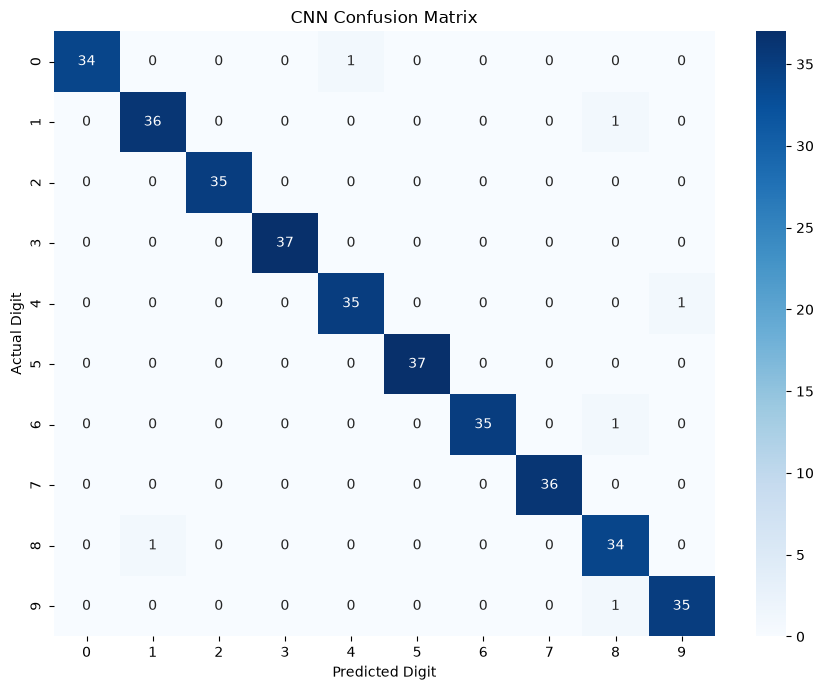

Total incorrect predictions: 6
First 10 errors: [{'actual': 1, 'predicted': 8}, {'actual': 0, 'predicted': 4}, {'actual': 9, 'predicted': 8}, {'actual': 4, 'predicted': 9}, {'actual': 6, 'predicted': 8}, {'actual': 8, 'predicted': 1}]
========== ViT TEST RESULTS ==========
Accuracy: 0.9667
Macro F1: 0.9666

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        35
           1       0.95      0.95      0.95        37
           2       0.94      0.94      0.94        35
           3       1.00      1.00      1.00        37
           4       0.92      1.00      0.96        36
           5       0.97      1.00      0.99        37
           6       0.97      0.97      0.97        36
           7       0.92      0.97      0.95        36
           8       1.00      0.94      0.97        35
           9       1.00      0.92      0.96        36

    accuracy                           0.97       360
   macro avg      

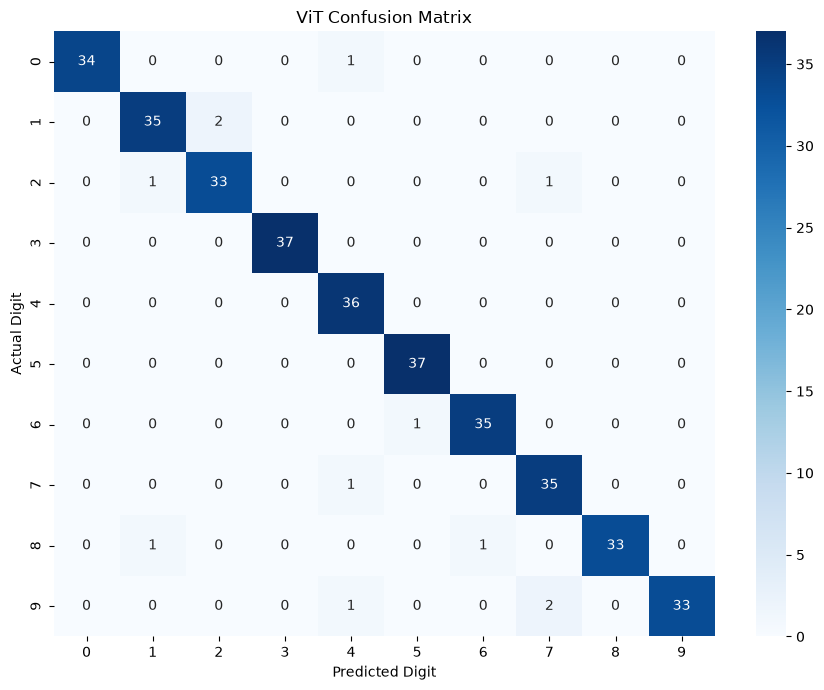

Total incorrect predictions: 12
First 10 errors: [{'actual': 8, 'predicted': 6}, {'actual': 9, 'predicted': 4}, {'actual': 6, 'predicted': 5}, {'actual': 1, 'predicted': 2}, {'actual': 0, 'predicted': 4}, {'actual': 9, 'predicted': 7}, {'actual': 2, 'predicted': 7}, {'actual': 2, 'predicted': 1}, {'actual': 1, 'predicted': 2}, {'actual': 7, 'predicted': 4}]


In [64]:
cnn_results = evaluate_model(cnn_model, "CNN")
vit_results = evaluate_model(vit_model, "ViT")


13. Save Evaluation Results and Training History

In [65]:
results = {
    "dataset": "sklearn digits",
    "split": {
        "train": int(len(X_train)),
        "validation": int(len(X_val)),
        "test": int(len(X_test))
    },
    "baseline": {
        "majority_class": majority_class,
        "accuracy": float(baseline_accuracy),
        "macro_f1": float(baseline_f1)
    },
    "CNN": cnn_results,
    "ViT": vit_results
}

with open("results/evaluation_results.json", "w") as file:
    json.dump(results, file, indent=4)

with open("results/training_history.json", "w") as file:
    json.dump(
        {"CNN": cnn_history, "ViT": vit_history},
        file,
        indent=4
    )

print("Evaluation results and training history saved.")


Evaluation results and training history saved.


14. Training Loss Comparison

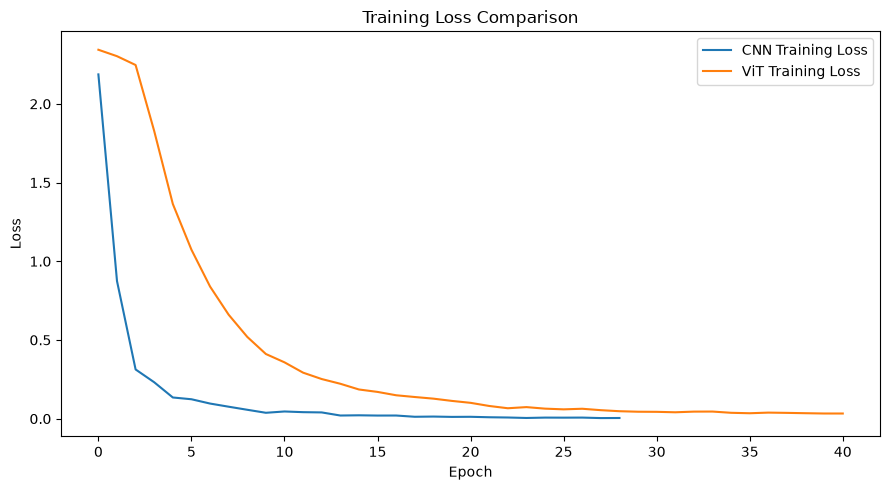

In [66]:
plt.figure(figsize=(9, 5))
plt.plot(cnn_history["train_loss"], label="CNN Training Loss")
plt.plot(vit_history["train_loss"], label="ViT Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss Comparison")
plt.legend()
plt.tight_layout()
plt.savefig("results/training_loss.png", dpi=150)
plt.show()
plt.close()


 15. Validation Accuracy Comparison

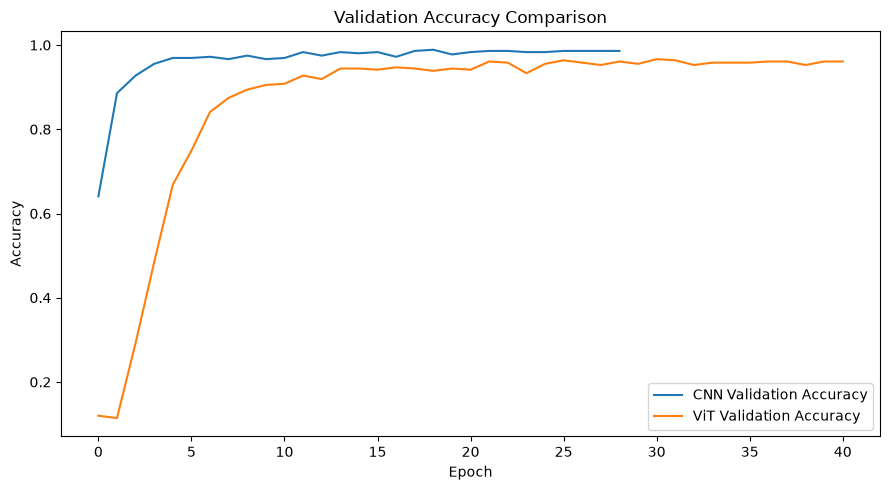

In [67]:
plt.figure(figsize=(9, 5))
plt.plot(cnn_history["val_accuracy"], label="CNN Validation Accuracy")
plt.plot(vit_history["val_accuracy"], label="ViT Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Validation Accuracy Comparison")
plt.legend()
plt.tight_layout()
plt.savefig("results/validation_accuracy.png", dpi=150)
plt.show()
plt.close()


 16. CNN vs ViT vs Majority Baseline

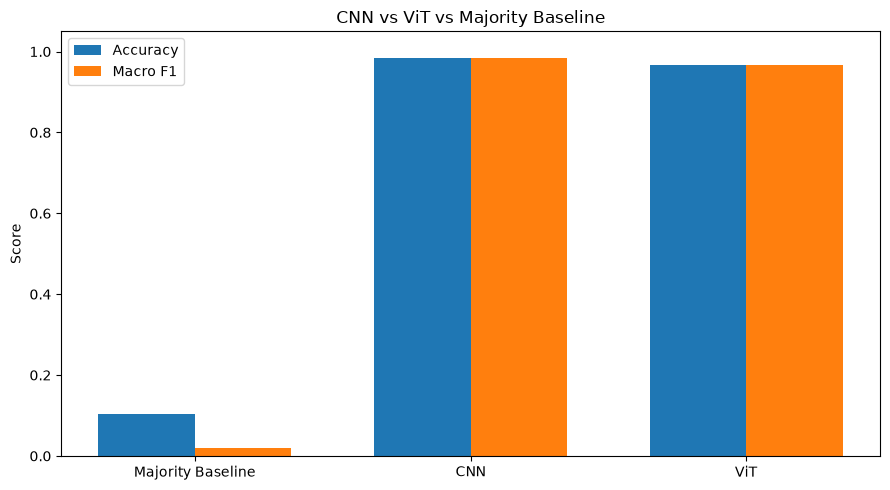

In [68]:
names = ["Majority Baseline", "CNN", "ViT"]
accuracies = [
    baseline_accuracy,
    cnn_results["accuracy"],
    vit_results["accuracy"]
]
f1_scores = [
    baseline_f1,
    cnn_results["macro_f1"],
    vit_results["macro_f1"]
]

x_axis = np.arange(len(names))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x_axis - width / 2, accuracies, width, label="Accuracy")
plt.bar(x_axis + width / 2, f1_scores, width, label="Macro F1")
plt.xticks(x_axis, names)
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("CNN vs ViT vs Majority Baseline")
plt.legend()
plt.tight_layout()
plt.savefig("results/comparison.png", dpi=150)
plt.show()
plt.close()


 17. Final Summary

In [69]:
print("CNN Test Accuracy:", cnn_results["accuracy"])
print("CNN Test Macro F1:", cnn_results["macro_f1"])
print("ViT Test Accuracy:", vit_results["accuracy"])
print("ViT Test Macro F1:", vit_results["macro_f1"])
print("\nCheckpoints saved in: models/")
print("Evaluation files saved in: results/")
print("\nGenerated files:")
for folder in ["models", "results"]:
    for filename in sorted(os.listdir(folder)):
        print(os.path.join(folder, filename))


CNN Test Accuracy: 0.9833333333333333
CNN Test Macro F1: 0.9833284601196419
ViT Test Accuracy: 0.9666666666666667
ViT Test Macro F1: 0.9666255144439289

Checkpoints saved in: models/
Evaluation files saved in: results/

Generated files:
models\__init__.py
models\__pycache__
models\cnn_model.pth
models\vit_model.pth
results\cnn_confusion_matrix.png
results\comparison.png
results\evaluation_results.json
results\training_history.json
results\training_loss.png
results\validation_accuracy.png
results\vit_confusion_matrix.png
